# Iris Dataset Assessment Notebook 

In [1]:
# Numerical arrays
import numpy as np
# Normal distribution
from scipy.stats import norm
# Machine learning library
import sklearn as skl 
# Iris dataset 
from sklearn.datasets import load_iris
# Python Data Analysis Library
import pandas as pd
# import data via pandas
iris = pd.read_csv("https://gist.githubusercontent.com/curran/a08a1080b88344b0c8a7/raw/0e7a9b0a5d22642a06d3d5b9bcbad9890c8ee534/iris.csv")
# Matplotlib for plotting 
import matplotlib.pyplot as plt 

In [2]:
# Load & return iris dataset from sklearn
data = load_iris() 

In [3]:
# Check dataset read in correctly from pandas
iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [4]:
# View target names
iris.species.unique()

<StringArray>
['setosa', 'versicolor', 'virginica']
Length: 3, dtype: str

In [5]:
# View data types
iris.dtypes

sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species             str
dtype: object

## Problem 1: Exploring Petal Length

This section investigates the distribution of petal_length in the iris dataset.

### Task 1. Petal length histogram

For this task, I plot a histogram of petal length for all 150 flowers in the dataset, using 10 bins. This shows the shape of the distribution, which I will compare with a normal distribution in Task 2.

In [6]:
# From pandas, access petal length
# using the bracket notation method 
# to plot feature
# Source: https://www.geeksforgeeks.org/pandas/pandas-access-columns/

# Extract Petal length from dataset
petal_length = iris["petal_length"] 

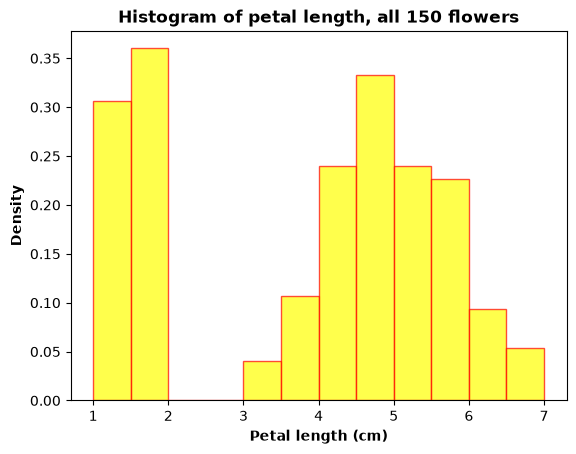

In [7]:
# Plot histogram
# Source: https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html
plt.hist(petal_length, bins=np.arange(1, 7.5, 0.5), 
         density=True, color='yellow', edgecolor='red', alpha=0.7)

# Add title & labels to axis
plt.xlabel("Petal length (cm)", fontweight='bold')
plt.ylabel("Density", fontweight='bold')
plt.title("Histogram of petal length, all 150 flowers", fontweight='bold')
plt.show()

### Task 2. Normal Distribution Overlay

To judge whether petal length is approximately normally distributed, I superimpose a normal curve on the histogram from Task 1. The curve uses the mean and standard deviation calculated from the petal length data, so it is the normal distribution that best matches the data's centre and spread.

- **Histogram scale:** The histogram is plotted with `density=True`, so the bar areas sum to 1. This puts it on the same scale as a probability density function. With raw counts, the curve would appear flat ([matplotlib](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html)). 
- **Normal curve:** `scipy.stats.norm.pdf(x, mean, std)` evaluates the normal probability density function at each x value ([Scipy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html)).
- **Standard deviation:** I use the sample standard deviation (`ddof=1`), which is the pandas default ([Pandas](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.std.html)).

In [8]:
# Mean and standard deviation
# Sources: 
# https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.std.html
# https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.mean.html
mean_pl = petal_length.mean()
std_pl = petal_length.std()

In [9]:
# x values spaced evenly across the data range; 
# 300 points was chosen so the curve looks smooth.
# Source: 
# https://numpy.org/doc/stable/reference/generated/numpy.linspace.html
x = np.linspace(petal_length.min() -1, petal_length.max() + 1, 300)

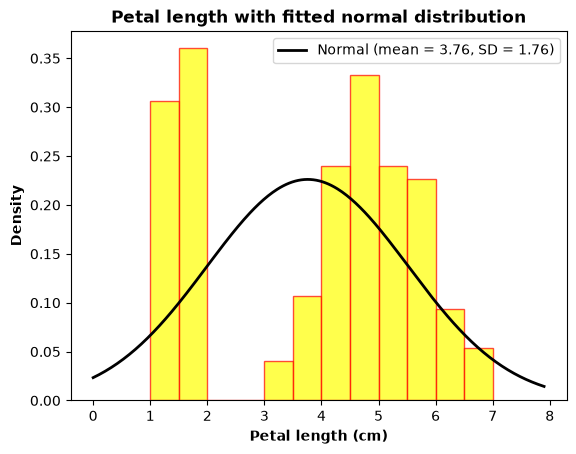

In [10]:
# Histogram on a density scale, so it is comparable with the curve
# Source: 
# https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html 
plt.hist(petal_length, bins=np.arange(1, 7.5, 0.5), density=True, 
         color='yellow', edgecolor='red', alpha=0.7) 

# Normal probability density function using the data's mean & SD
# Source: 
# https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html
plt.plot(x, norm.pdf(x, mean_pl, std_pl), color='black', linewidth=2,
         label=f"Normal (mean = {mean_pl:.2f}, SD = {std_pl:.2f})") 

plt.xlabel("Petal length (cm)", fontweight='bold')
plt.ylabel("Density", fontweight='bold')
plt.title("Petal length with fitted normal distribution", fontweight='bold')
plt.legend()

### Task 3. Petal length histograms by species

The histograms in Task 1 & 2 pooled all 150 flowers and showed two distinct peaks. Here I test whether that shape comes from mixing three different groups rather than from the petal length measurement itself. I plot one histogram per species, with a fitted normal (bell-curve) distribution overlaid.

As in Task 2, each histogram is plotted with `density=True` so that it is on the same scale as the normal curve, which is calculated with `scipy.stats.norm.pdf`. I used 8 bins per species, since there are only 50 flowers in each and 10 bins would leave many bins nearly empty. The same bin count is used for all so they can be compared fairly.

In [11]:
# The data for each species is selected with `DataFrame.loc`, 
# which filters rows using a boolean condition on the `species` column 
# Source: 
# https://pandas.pydata.org/pandas-docs/version/2.1/reference/api/pandas.DataFrame.iloc.html 
setosa = iris.loc[iris["species"] == "setosa", "petal_length"]
versicolor = iris.loc[iris["species"] == "versicolor", "petal_length"]
virginica = iris.loc[iris["species"] == "virginica", "petal_length"]

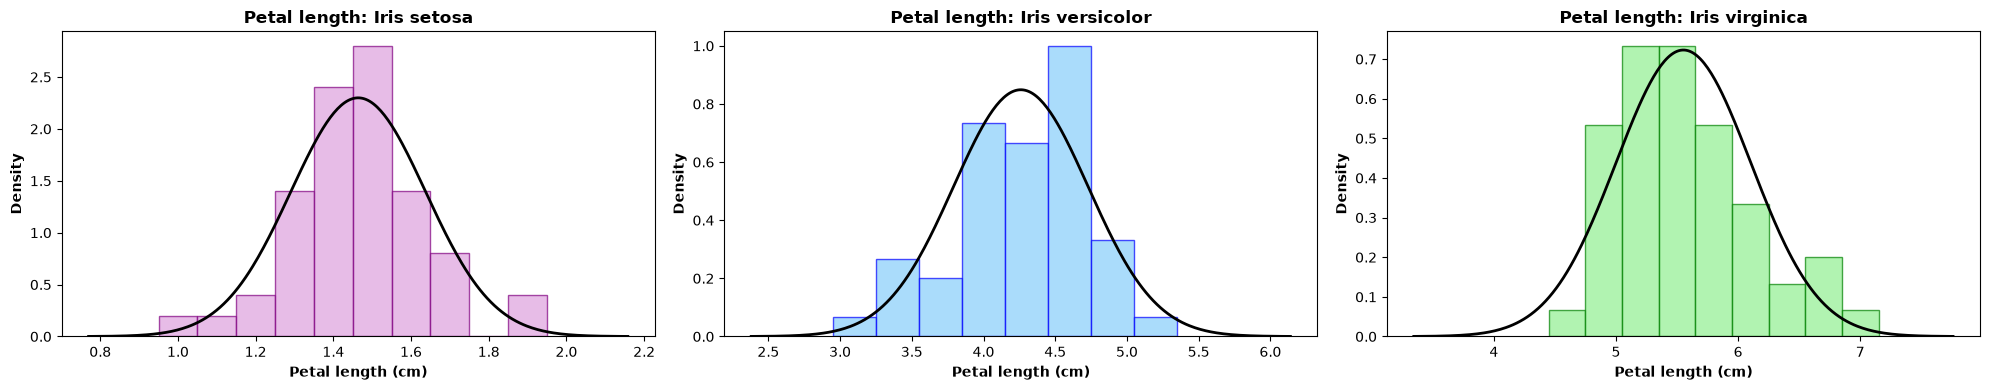

In [12]:
# Create one figure (`fig`) containing a grid of 1 row 
# and 3columns of plot areas. `axes` is an array of 
# the four plot areas, and `figsize` sets the overall size in inches (20 wide, 4 tall).
# Source:
# https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html
fig, axes = plt.subplots(1, 3, figsize=(20, 4))

# Each species is stored as a tuple: (title, data, fill colour, edge colour, bin edges).
# List-of-tuples structure adapted from:
# https://www.geeksforgeeks.org/python/creating-a-pandas-dataframe-using-list-of-tuples/
# Bin edges set with np.arange (start, stop, step), placed between the 0.1 cm
# measurement values: https://numpy.org/doc/stable/reference/generated/numpy.arange.html
groups = [
    ("Iris setosa", setosa, "plum", "purple", np.arange(0.95, 2.0, 0.1)),
    ("Iris versicolor", versicolor, "lightskyblue", "blue", np.arange(2.95, 5.4, 0.3)),
    ("Iris virginica", virginica, "lightgreen", "green", np.arange(4.45, 7.2, 0.3)),
]

# Loop over the three panels. `zip` pairs each plot area with its tuple, 
# and the tuple is unpacked into three named variables.
# Source:
# https://docs.python.org/3/library/functions.html#zip
for ax, (name, data, fill, edge, bins) in zip(axes, groups):
    mu, sd = data.mean(), data.std()

    ax.hist(data, bins=bins, density=True, color=fill, alpha=0.7, edgecolor=edge)
    
    x = np.linspace(mu - 4*sd, mu + 4*sd, 300) #300 evenly spaced x-values from 4 SDs below the mean to 4 SDs above it.
    ax.plot(x, norm.pdf(x, mu, sd), "black", linewidth=2)

    ax.set_title(f"Petal length: {name}", fontweight="bold")
    ax.set_xlabel("Petal length (cm)", fontweight="bold")
    ax.set_ylabel("Density", fontweight="bold")

plt.tight_layout()
plt.show()

Within each species the data has a single peak, and the fitted normal curves follow the
histograms much more closely than the overall curve did in Task 2. Setosa has much shorter
petals and is tightly clustered, while versicolor and virginica have longer
petals and a wider spread. The fit is not perfect, which is expected
with only 50 flowers per species. The fuller comparison is in Task 5.

### Task 4. Petal Length - Mean & SD

The table below gives the mean and standard deviation of petal length (in cm) for the full dataset and for each species.

In [13]:
# `.agg(["mean", "std"])` calculates the mean and sample standard 
# deviation of all 150 petal lengths. 
# The result is converted to a single-row DataFrame with 
# `.to_frame().T` so it can be stacked with the per-species table, 
# Sources;
# https://pandas.pydata.org/pandas-docs/version/2.1/reference/api/pandas.DataFrame.agg.html
# https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.to_frame.html
# https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.T.html 
overall = iris["petal_length"].agg(["mean", "std"]).to_frame().T
# Row renamed so the combined table reads clearly
overall.index = ["All species"]

# Mean and sample standard deviation for each species
# `iris.groupby("species")` splits the DataFrame into one group per species
# Source:
# https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.groupby.html
by_species = iris.groupby("species")["petal_length"].agg(["mean", "std"])

#`pd.concat([overall, by_species])` joins the two tables vertically, 
# placing the "All species" row above the three species rows
# Source: https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.concat.html
summary = pd.concat([overall, by_species])
# Rename the columns for clarity
summary.columns = ["Mean (cm)", "Standard deviation (cm)"]

# Display the table rounded to 2 decimal places
summary.round(2)

,Mean (cm),Standard deviation (cm)
All species,3.76,1.76
setosa,1.46,0.17
versicolor,4.26,0.47
virginica,5.55,0.55


The overall standard deviation is much larger than any within-species value, reflecting the large differences in mean petal length between species.

### Task 5. Evaluating the normal model for petal length

Overall petal length is clearly bimodal: a tall peak at 1-2 cm, an empty gap between 2 and 3 cm, and a broader peak at 4-6 cm. The fitted normal curve (mean 3.76, SD 1.76) is a poor model. It peaks near 3.8 cm, where data are sparse, and underestimates the spike near 1.5 cm. Its tails extend below zero, assigning probability to impossible negative lengths, and beyond the observed range of about 1-7 cm. The large SD reflects the separation between species rather than natural variation, so the pooled data are a mixture of subpopulations.  

Within each species the distribution is unimodal and roughly symmetric, and the normal curve is a reasonable fit. Setosa (mean 1.46, SD 0.17) is very tight and follows the normal curve closely. Versicolor (mean 4.26, SD 0.47) is slightly left-skewed, with a tail towards 3 cm. Virginica (mean 5.55, SD 0.55) has a single hump with a mild right tail. Small irregularities in all three are plausibly sampling noise given only 50 flowers each. Setosa is much smaller and less variable than the other two, which have similar spreads and overlap slightly. The panels use different axes, so these differences are best read from the table of means and SDs.

In conclusion, a single normal distribution is not appropriate for petal length overall, but a normal model is reasonable within each species.

## Problem 2: Correlation Between Petal Length and Petal Width

In this section, I investigate the relationship between petal_length and petal_width in the Iris dataset.

### Task 1. Pearson correlation coefficient - Petal Length and Petal Width

For this task, I will calculate the Pearson correlation coefficient, to measure the strength & direction of the relationship between Petal Length and Petal Width of all 150 flowers.
To carry out this calculation, I will use the `pandas.DataFrame.corr` method which computes the Pearson correlation by default ([Pandas](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.corr.html)).
I will then display the result using the F-String method to 3 decimal places as shown by [GeeksforGeeks](https://www.geeksforgeeks.org/python/precision-handling-python/).

In [14]:
# Calculate the Pearson correlation coefficient between petal length and petal width
pearson_r = iris["petal_length"].corr(iris["petal_width"])
print(f"Pearson r = {pearson_r:.3f}")

Pearson r = 0.963


The Pearson correlation coefficient of r = 0.963 indicates a very strong positive linear relationship. However, a single coefficient cannot show whether the relationship is genuinely linear, whether outliers are influencing it, or whether the data form distinct groups. In Task 2, I will therefore first plot petal width against petal length as a scatter plot using a suitable line to summarise the relationship.

### Task 2. Scatter Plot with Line - Petal length & petal width 

In this task, I plot petal width against petal length for all 150 flowers as a scatter, where each point is one flower. I will first draw the scatter plot on its own and examine it, and then choose a line to help illustrate the relationship.

I use `matplotlib` to create the scatter plot. `plt.subplots(figsize=(7, 5))` creates a figure 7 inches wide and 5 inches tall, containing one plot area (`ax`) that I then customise. `ax.scatter()` draws one purple point per flower, with petal length from the iris DataFrame on the x-axis and petal width on the y-axis, and `edgecolor="white"` outlines each point so neighbouring points stay distinct. `ax.set_title()`, `ax.set_xlabel()` and `ax.set_ylabel()` add a bold title and axis labels that include the units (cm).

References used to create scatterplot:
[Matplotlib.pyplot.subplots](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html), [Matplotlib.scatter](https://matplotlib.org/stable/plot_types/basic/scatter_plot.html)


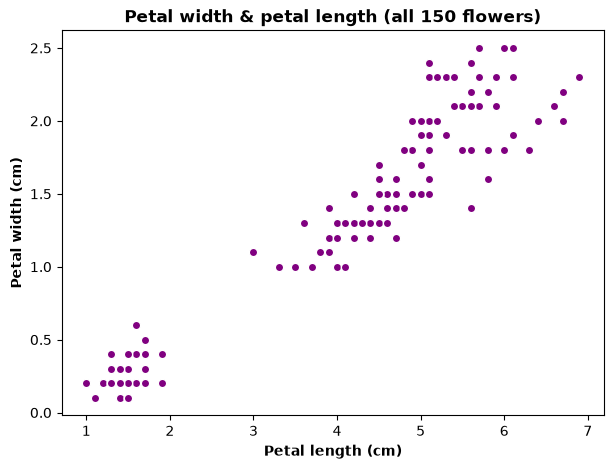

In [15]:
fig, ax = plt.subplots(figsize=(7, 5)) # Create new figure and axes for the scatter plot

ax.scatter(iris["petal_length"], iris["petal_width"], # Plot the scatter points
           color="purple", edgecolor="white")

# Add title and axis labels
ax.set_title("Petal width & petal length (all 150 flowers)", 
             fontweight="bold")
ax.set_xlabel("Petal length (cm)", fontweight="bold")
ax.set_ylabel("Petal width (cm)", fontweight="bold")
plt.show()

The points rise in a roughly straight band with no obvious curvature, so a straight line is a suitable summary of the relationship. I will therefore use a least-squares line, the standard way to fit a straight line to data. The least-squares line minimises the sum of squared vertical distances between the points and the line ([GeeksforGeeks](https://www.geeksforgeeks.org/maths/least-square-method-practice-questions/)).

First, I fit it with `numpy.polyfit` (degree 1), which returns the slope and intercept, following [NumPy Documentation](https://numpy.org/doc/stable/reference/generated/numpy.polyfit.html).

In [16]:
# Fit a least-squares regression line to the data
slope, intercept = np.polyfit(iris["petal_length"], iris["petal_width"], 1)
print(f"slope = {slope:.3f}, intercept = {intercept:.3f}")

slope = 0.416, intercept = -0.367


To add the line, I first redraw the scatter plot with `ax.scatter`, so the points and the line share the same axes. The line is then built from the slope and intercept calculated earlier by `np.polyfit`.  
`np.linspace(min, max, 100)` creates 100 evenly spaced x-values from the shortest to the longest petal length in the data, so the line covers the observed range and no further. - [NumPy Documentation](https://numpy.org/doc/stable/reference/generated/numpy.linspace.html).  
For each of these x-values, `slope * x_line + intercept` calculates the matching y-value on the straight line `y = slope * x + intercept`.  
`ax.plot(x_line, y_values, ...)` then draws these points joined together as a continuous black line (`color="black"`, `linewidth=2`) on top of the scatter plot.  
The `label=f"slope = {slope:.3f}, intercept = {intercept:+.3f}")` argument displays the slope & intercept, and `ax.legend()` displays them in a legend box.

To add the regression line to scatterplot, I modified the code displayed on [Statology](https://www.statology.org/scatterplot-with-regression-line-python/). 

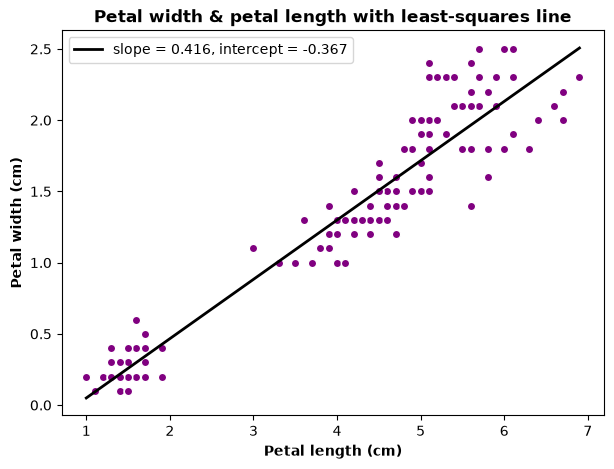

In [17]:
fig, ax = plt.subplots(figsize=(7, 5)) # Create new figure and axes for the scatter plot and regression line

ax.scatter(iris["petal_length"], iris["petal_width"], # Plot the scatter points
           color="purple", edgecolor="white")

x_line = np.linspace(iris["petal_length"].min(), iris["petal_length"].max(), 100) # Generate x values for the regression line
ax.plot(x_line, slope * x_line + intercept, color="black", linewidth=2, # Plot the regression line
        label=f"slope = {slope:.3f}, intercept = {intercept:+.3f}")

# Add title, axis labels, and legend
ax.set_title("Petal width & petal length with least-squares line", fontweight="bold")
ax.set_xlabel("Petal length (cm)", fontweight="bold")
ax.set_ylabel("Petal width (cm)", fontweight="bold")
ax.legend()
plt.show()

The least-squares line follows the points closely, with a slope of 0.416, so each extra 1 cm of petal length goes with about 0.42 cm more petal width on average. However, the points form two separate groups, so this single line may reflect differences between groups rather than the relationship within each. In Task 3, I therefore calculate the correlation separately for each species.

### Task 3. Pearson correlation coefficient - Petal Length and Petal Width By Species

For this task, I will calculate the Pearson correlation coefficient separately for each of the three species, to see whether the relationship between petal length and petal width is the same within each species as it is across all 150 flowers. I use a `for` loop ([Real Python](https://realpython.com/python-for-loop/)) over the species names returned by `pandas.Series.unique` ([Pandas](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.unique.html)), so the species are read from the data rather than typed in. On each pass, I select that species' rows using boolean indexing ([GeeksforGeeks](https://www.geeksforgeeks.org/pandas/boolean-indexing-in-pandas/)) and calculate the correlation with `pandas.Series.corr` ([Pandas](([Pandas](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.corr.html)))). The result is printed with an f-string to 3 decimal places, as in Task 1.

In [18]:
# Loop over each distinct species name found in the "species" column
for sp in iris["species"].unique():
    # Keep only the rows (50 flowers) belonging to the current species
    sub = iris[iris["species"] == sp]
    # Pearson correlation between petal length and petal width for this species
    r = sub["petal_length"].corr(sub["petal_width"])
    # Print the species name and r, rounded to 3 decimal places
    print(f"{sp}: r = {r:.3f}")

setosa: r = 0.306
versicolor: r = 0.787
virginica: r = 0.322


Within each species, the correlation is weaker than the overall r = 0.963. In Task 4, I therefore plot petal width against petal length for each species to see these within-species relationships visually.

### Task 4. Scatter Plot by Species - Petal Length and Petal Width

In this task, I plot petal width against petal length for all 150 flowers on a single set of axes, with a separate colour and marker shape for each species.

To plot each species separately, I loop over a dictionary that maps each species name to a colour, and a second dictionary that maps each species name to a marker shape (circle, square & triangle) ([See Matplotlib](https://matplotlib.org/stable/api/markers_api.html)).

In [19]:
# Colour and marker used for each species
colours = {"setosa": "purple", "versicolor": "blue", "virginica": "green"}
markers = {"setosa": "o", "versicolor": "s", "virginica": "^"}

I then create the figure and axes with `matplotlib.pyplot.subplots` ([See Matplotlib](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html)). With no row or column arguments it makes a single plot area, 8 inches wide and 5 inches tall (`figsize=(8, 5)`), and all three species are drawn on it.

The `for` loop ([See Python Documentation](https://docs.python.org/3/tutorial/controlflow.html#for-statements)) uses the dictionary's `items()` method ([See w3schools](https://www.w3schools.com/python/ref_dictionary_items.asp)) to give both the species name (`sp`) and its colour (`col`) on each pass. Inside the loop, `iris[iris["species"] == sp]` uses boolean indexing ([GeeksforGeeks](https://www.geeksforgeeks.org/pandas/boolean-indexing-in-pandas/)) to keep only the rows for the current species, stored in `sub`, so each species can be drawn with its own colour, marker and legend label.

For each species I draw its points with `ax.scatter` ([See Matplotlib Documentation](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.scatter.html)). The `marker` argument gives each species a different shape, `s=70` sets the marker size, and `alpha=0.7` makes the points slightly transparent so that overlapping points remain visible ([See Matplotlib](https://matplotlib.org/stable/api/markers_api.html)). `edgecolor="white"` outlines each point, and `label=sp` provides the name used in the legend.

Finally, `ax.set_title`, `ax.set_xlabel` and `ax.set_ylabel` add a bold title and axis labels with units, `ax.grid(alpha=0.3)` adds a light grid to make values easier to read from the axes ([See GeeksforGeeks](https://www.geeksforgeeks.org/python/grids-in-matplotlib/)), and `ax.legend(title="Species")` displays the legend identifying each species.

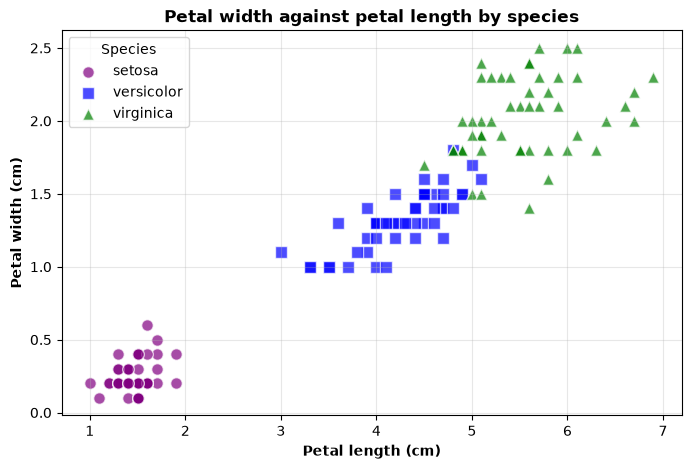

In [20]:
# Create a new figure and axes for scatter plot
fig, ax = plt.subplots(figsize=(8, 5))

# Plot each species separately so it gets its own colour and legend entry
for sp, col in colours.items():
    # Keep only the rows for the current species
    sub = iris[iris["species"] == sp]
    ax.scatter(
        sub["petal_length"], sub["petal_width"],
        color=col, marker=markers[sp], s=70, alpha=0.7,
        edgecolor="white", label=sp)

# Add title, axis labels, grid, and legend 
ax.set_title("Petal width against petal length by species",
             fontweight="bold")
ax.set_xlabel("Petal length (cm)", fontweight="bold")
ax.set_ylabel("Petal width (cm)", fontweight="bold")
ax.grid(alpha=0.3)
ax.legend(title="Species")
plt.show()

### Task 5. Comparing Correlations - Petal Length and Petal Width

The table below brings together the Pearson correlation coefficients between petal length and petal width from Tasks 1 and 3:

| Group           | Pearson r | Strength           |
|:----------------|----------:|:-------------------|
| **All species** |     0.963 | Very strong        |
| *Setosa*        |     0.306 | Weak to moderate   |
| *Versicolor*    |     0.787 | Strong             |
| *Virginica*     |     0.322 | Weak to moderate   |

The overall correlation (r = 0.963) is much higher than the correlation within any single species. *Versicolor* has the strongest within-species correlation (r = 0.787), while *Setosa* (r = 0.306) and *Virginica* (r = 0.322) are much weaker and very similar to each other. All four coefficients are positive, so longer petals tend to go with wider petals in every case, but the strength of the relationship varies a lot.

### Task 6. Interpreting the Correlation Coefficients

Explain what the correlation coefficients tell you about the relationship between petal length and petal width, both for the dataset as a whole and within each species.

## Problem 3: Comparing Species Using t-Tests

Investigate whether the three iris species differ in their petal_length and petal_width.

For each pair of species:
- setosa vs versicolor
- setosa vs virginica
- versicolor vs virginica

Perform an independent-samples t-test for:
- petal length
- petal width

For each test:
- State the null and alternative hypotheses.
- Calculate the t-statistic and p-value using scipy.stats.
- Use a significance level of α=0.05 to decide whether to reject the null hypothesis.
- Summarise your results in an appropriate table.
- Explain what the results tell you about differences between the three species.

## Problem 4: Comparing the Species Using ANOVA

The t-tests in Problem 3 require several separate comparisons between species. Instead, investigate differences in petal length and petal width using one-way analysis of variance (ANOVA).

For each variable:

- State the null and alternative hypotheses for a one-way ANOVA.
- Perform a one-way ANOVA comparing the three species using scipy.stats.
- Report the F-statistic and p-value.
- Use a significance level of α=0.05 to determine whether there is evidence that the species have different population means.
- Explain what the ANOVA result tells you and what it does not tell you about the individual species.

The t-tests in Problem 3 involved three pairwise comparisons. Explain why performing several separate hypothesis tests can increase the overall probability of making a type I error, and explain how ANOVA addresses this problem by testing the three group means simultaneously.

Finally, compare the conclusions from your t-tests with those from the ANOVA and explain why ANOVA is generally preferable when comparing more than two groups.

## End